# Data Understanding — AI4I Predictive Maintenance Analytics

I begin by inspecting the AI4I 2020 dataset to understand its structure, variables, and failure labels. This gives me a foundation for exploratory analysis, cleaning, and model development.

**Input:** `data/ai4i2020.csv`  
**Project:** AI4I Predictive Maintenance Analytics

I work with the raw CSV at this stage and leave its values unchanged.


## 1. Load the dataset

I load the CSV with pandas and preview the first five observations. The project-root lookup allows me to run the notebook from either the project folder or its `notebook` folder.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (8, 5)

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "data" / "ai4i2020.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/ai4i2020.csv. Open this notebook inside the project folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "ai4i2020.csv"
df = pd.read_csv(DATA_PATH)
if df.empty:
    raise ValueError("The CSV contains no observations.")
if "Machine failure" not in df.columns:
    raise ValueError("The CSV is missing the Machine failure target column.")

print(f"Loaded {len(df):,} observations from {DATA_PATH.name}")
display(df.head())


Loaded 10,000 observations from ai4i2020.csv


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Inspect the dataset structure

I inspect the number of rows and columns, column names, data types, and non-null counts. I use this information to distinguish measurements, categories, identifiers, and outcome labels.


In [2]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()


Rows: 10,000
Columns: 14

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      1

## 3. Understand the variable roles

| Role | Columns | How I will use them |
|---|---|---|
| Identifiers | UDI, Product ID | Trace observations; exclude from prediction inputs |
| Product category | Type | Examine differences between L, M, and H groups |
| Sensor measurements | Air temperature, process temperature, rotational speed, torque, tool wear | Explore as candidate prediction inputs |
| Overall outcome | Machine failure | Use as the binary classification target |
| Failure indicators | TWF, HDF, PWF, OSF, RNF | Analyze failure categories; exclude from prediction inputs |

The AI4I data are synthetic. I treat the observed associations as properties of this dataset and evaluate model performance separately in later stages.


## 4. Review descriptive statistics

I summarize numeric and categorical variables to inspect their ranges, spread, and distinct values. Unusual measurements are candidates for investigation rather than automatic removal.


In [3]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,L57163,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


## 5. Check the failure target

I verify that `Machine failure` contains only 0 and 1, then calculate class counts and percentages. I compare the class balance with the accuracy of always predicting no failure.


In [4]:
if not df["Machine failure"].isin([0, 1]).all():
    raise ValueError("Machine failure must contain only 0 and 1, without missing labels.")

counts = df["Machine failure"].value_counts().reindex([0, 1], fill_value=0)
failure_rate = float(df["Machine failure"].mean())
target_summary = pd.DataFrame({
    "count": counts,
    "percentage": counts / len(df) * 100,
}).rename(index={0: "No failure", 1: "Failure"})

display(target_summary.round(2))
print(f"Failure rate: {failure_rate:.2%}")
print(f"Always predicting no failure would give {1 - failure_rate:.2%} accuracy.")


,count,percentage
Machine failure,,
No failure,9661,96.61
Failure,339,3.39


Failure rate: 3.39%
Always predicting no failure would give 96.61% accuracy.


## 6. Visualize the class balance

I plot the counts and percentages together so I can see how common failure observations are relative to normal observations.


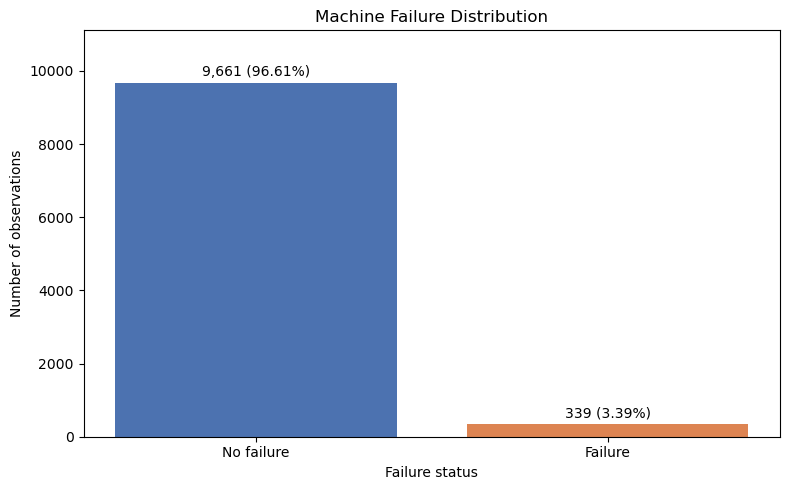

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(target_summary.index, counts.values, color=["#4C72B0", "#DD8452"])
for bar, count, percentage in zip(bars, counts, target_summary["percentage"]):
    ax.annotate(
        f"{count:,} ({percentage:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points", ha="center",
    )
ax.set_ylim(0, max(counts) * 1.15)
ax.set_title("Machine Failure Distribution")
ax.set_xlabel("Failure status")
ax.set_ylabel("Number of observations")
plt.tight_layout()
plt.show()
plt.close(fig)


## Findings and next steps

Failures form a small share of the observations in this dataset. I will assess precision, recall, F1, and precision–recall performance alongside accuracy when I build classifiers.

Next, I explore sensor distributions and their relationships with failure, then validate data quality and document any cleaning decisions. I keep identifiers and outcome-specific failure flags out of future prediction inputs.
